# Section 1: Latent Space Learning

Train (or load) a 2D Isometric AutoEncoder over 30 humanoid robots' 120-D symmetric screw vectors,
producing a geometry-preserving latent design space.

**Source**: `notebook/ae_test/ae_final.ipynb` cells 6-14
**Paper**: arXiv:2604.08636v1 §IV-D ("Design Manifold Learning")

## What you get
- A 2D latent embedding of 30 robots (Paper Fig 3 style)
- An AutoEncoder that can decode any z ∈ ℝ² into a 120-D screw vector → robot kinematic structure
- (Optional) Training loss curve if you opt into re-training

## Safety
- Default: `SKIP_TRAINING=True` → loads pretrained `canonical/model_dir/model.pt` (≈2 min total)
- `SKIP_TRAINING=False, SAVE_OUTPUTS=True` → re-trains and writes to `outputs/model.pt` (≈10 min on CUDA, ≈30 min on CPU)
- **Never overwrites canonical `result/h64_32_z2_isoTrue_.../model.pt`**


In [1]:
# ---- Tutorial flags (edit these to control behavior) ----
SAVE_OUTPUTS  = False    # if True, write artifacts to ./outputs/ (NOT to project canonical paths)
SKIP_TRAINING = True     # if True, load pretrained model from ./canonical/model_dir/

# ---- Path setup ----
import os, sys
HERE = os.path.abspath('.')                          # notebook/tutorial/
REPO = os.path.abspath('../../')                     # project root
for p in ['package','package/yoon','package/mujoco_helper','package/kinematics_helper',
          'package/utility','package/bvh_helper','package/smpl','package/motion_retarget',
          'package/irvae_tools','package/kinematics','asset']:
    sys.path.insert(0, os.path.join(REPO, p))
sys.path.insert(0, HERE)

CANONICAL   = os.path.join(HERE, 'canonical/')
TUTORIAL_OUT = os.path.join(HERE, 'outputs/')
if SAVE_OUTPUTS:
    os.makedirs(TUTORIAL_OUT, exist_ok=True)

# RobotCharacteristics uses ../../asset/_robot_info/A-pose.json (relative path inside its module)
os.chdir(os.path.join(REPO, 'notebook/ae_test'))

import numpy as np
import torch as th
import torch.nn as nn
import matplotlib.pyplot as plt

from data_utils import load_saved_model, load_data_subset, show_data_matrix
from ae import AutoEncoderClass, run_experiment
from clustering_robots import RobotCharacteristics

print(f'SAVE_OUTPUTS  = {SAVE_OUTPUTS}')
print(f'SKIP_TRAINING = {SKIP_TRAINING}')
print(f'canonical:    {CANONICAL}')
print(f'tutorial out: {TUTORIAL_OUT}')

SAVE_OUTPUTS  = False
SKIP_TRAINING = True
canonical:    <LEGO_code>/notebook/tutorial/canonical/
tutorial out: <LEGO_code>/notebook/tutorial/outputs/


## 1. Load symmetric 120-D data

The 30 training robots are stored as `(30, 30, 6)` screw arrays (axis + position per joint slot,
30 slots/robot). We extract the **symmetric subset** (torso + neck + right-side groups only;
left side is reconstructed by mirroring) to get `(30, 120)`.

| slot index | groups | size |
|---|---|---|
| 0-5  | torso (6) | 6×6 = 36D |
| 6-9  | neck (4)  | 4×6 = 24D |
| 20-29 | right-side: shoulder_girdle(1) + shoulder(3) + upperarm(1) + elbow(1) + forearm(1) + wrist(3) | 10×6 = 60D |
| **total** | 20 slots | **120D** ✓ |

In [2]:
repr_kind = 'screw'
data_path = os.path.join(CANONICAL, 'data', repr_kind) + '/'
data = load_data_subset(data_path)
print(f'data shape: {data.shape}')
print(f'(N, D) = (30 robots, 20 slots × 6 features = 120D)')

data shape: (30, 120)
(N, D) = (30 robots, 20 slots × 6 features = 120D)


## 2. Inspect data matrix

Heatmap of the 30×120 input: rows are robots, columns are screw features in order
[torso(6×6), neck(4×6), right-side(10×6)]. Sparsity reveals which slots are anchors vs valid joints.

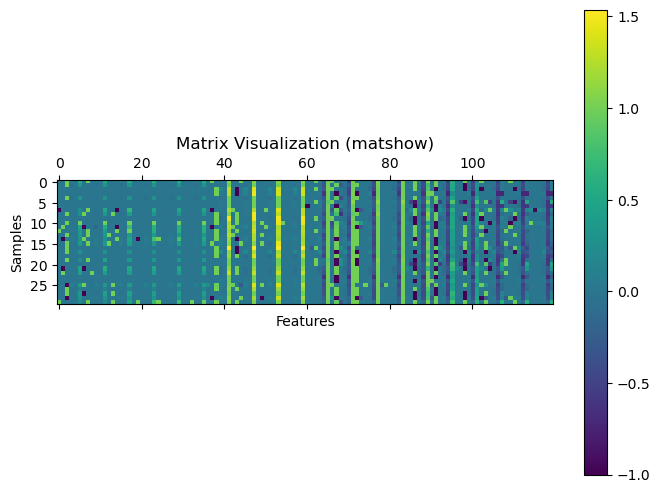

In [3]:
fig = show_data_matrix(data, cmap='viridis')
plt.show()

## 3. Build (or load) the AutoEncoder

Architecture (paper §IV-D):
- Input: 120D
- Hidden: 64 → 32
- Latent: z = 2 (main result); z = 3 for ablation
- Activation: Tanh
- Loss: L2 reconstruction + λ_iso · `relaxed_distortion_measure`
- λ_iso = 1e-7, η = 0.2

If `SKIP_TRAINING=True`, we load the pretrained checkpoint from `canonical/model_dir/`.

In [4]:
if SKIP_TRAINING:
    model_name = 'h64_32_z2_isoTrue_actvTanh_isoreg1e-07_nepoch1000_bs10'
    ae, config = load_saved_model(model_name=model_name, device='cpu')
    print(f'Loaded pretrained AE: {model_name}')
    print(f'  z_dim = {ae.z_dim}, h_dims = {ae.h_dims}, iso = {ae.iso}, iso_reg = {ae.iso_reg}')
else:
    # New models are written to ./outputs/models/ (gitignored), never to result/,
    # so the pretrained checkpoint above is never overwritten.
    train_root = os.path.join(TUTORIAL_OUT, 'models')
    print(f'Training from scratch (save_root = {train_root})...')
    results, model_name = run_experiment(
        data_np=data,
        h_dims=[64, 32], z_dim=2,
        num_epochs=1000, lr=1e-3,
        actv=nn.Tanh(), loss_type='l2',
        device='cuda:0' if th.cuda.is_available() else 'cpu',
        batch_size=10,
        iso=True, iso_reg=1e-7,
        save_root=train_root,
    )
    ae, config = load_saved_model(model_name=model_name, device='cpu', root=train_root)
    print(f'Trained: {train_root}/{model_name}')


Loaded pretrained AE: h64_32_z2_isoTrue_actvTanh_isoreg1e-07_nepoch1000_bs10
  z_dim = 2, h_dims = [64, 32], iso = True, iso_reg = 1e-07


## 4. Encode 30 robots into latent space

Each robot maps to one point z ∈ ℝ². The whole dataset lives on a 2D manifold.

Latent shape: (30, 2)
Range: x ∈ [-10.43, 9.48], y ∈ [-9.61, 12.67]


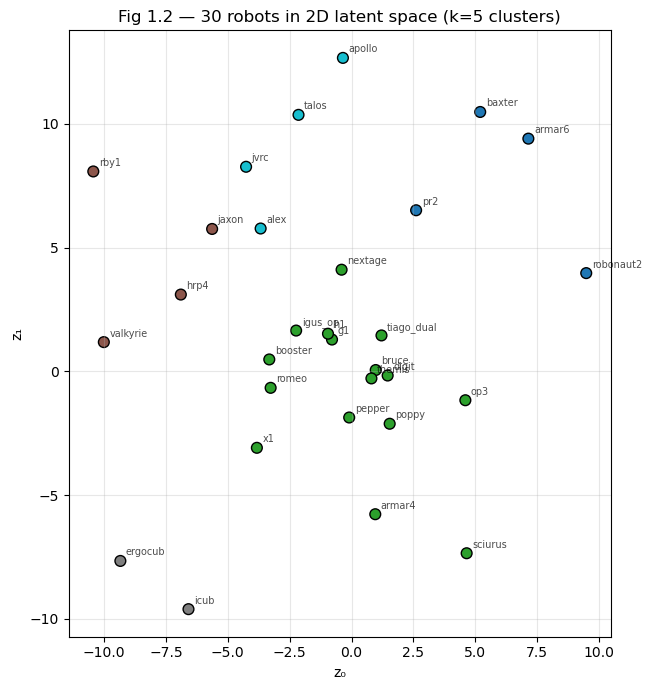

In [5]:
label_data = np.load(os.path.join(CANONICAL, 'data', repr_kind, 'label.npy'))

with th.no_grad():
    z_all = ae.encode(th.tensor(data, dtype=th.float32)).numpy()
print(f'Latent shape: {z_all.shape}')
print(f'Range: x ∈ [{z_all[:,0].min():.2f}, {z_all[:,0].max():.2f}], '
      f'y ∈ [{z_all[:,1].min():.2f}, {z_all[:,1].max():.2f}]')

# --- Fig 1.2: 2D latent scatter with k=5 cluster ---
from sklearn.cluster import KMeans
km = KMeans(n_clusters=5, random_state=42, n_init=10).fit(z_all)

fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(z_all[:, 0], z_all[:, 1], c=km.labels_, cmap='tab10', s=60, edgecolors='k')
for i, name in enumerate(label_data):
    ax.annotate(str(name), z_all[i], fontsize=7, alpha=0.7,
                xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('z₀'); ax.set_ylabel('z₁')
ax.set_title('Fig 1.2: 30 robots in 2D latent space (k=5 clusters)')
ax.grid(alpha=0.3); ax.set_aspect('equal')
plt.tight_layout()
plt.show()

## 5. Reconstruction check

For a few representative robots, compare original input vs `decoder(encoder(x))`.

Reconstruction error per robot (L2):
  [ 0] talos        err=0.3704
  [ 1] g1           err=0.6029
  [ 2] tiago_dual   err=0.3435
  [ 3] op3          err=0.3538
  [ 4] h1           err=0.6234
  [ 5] baxter       err=0.3876
  [ 6] digit        err=1.1514
  [ 7] ergocub      err=0.2890
  [ 8] alex         err=1.6070
  [ 9] pr2          err=0.6383
  [10] romeo        err=0.3523
  [11] icub         err=0.1467
  [12] jaxon        err=0.8315
  [13] jvrc         err=0.9637
  [14] poppy        err=0.2538
  [15] valkyrie     err=0.2160
  [16] nextage      err=0.6188
  [17] sciurus      err=0.2557
  [18] igus_op      err=0.9456
  [19] armar4       err=0.3431
  [20] armar6       err=0.2247
  [21] pepper       err=3.2293
  [22] hrp4         err=0.3016
  [23] bruce        err=1.1627
  [24] themis       err=1.1007
  [25] apollo       err=0.1820
  [26] booster      err=0.5316
  [27] x1           err=0.9553
  [28] robonaut2    err=0.1536
  [29] rby1         err=1.0476


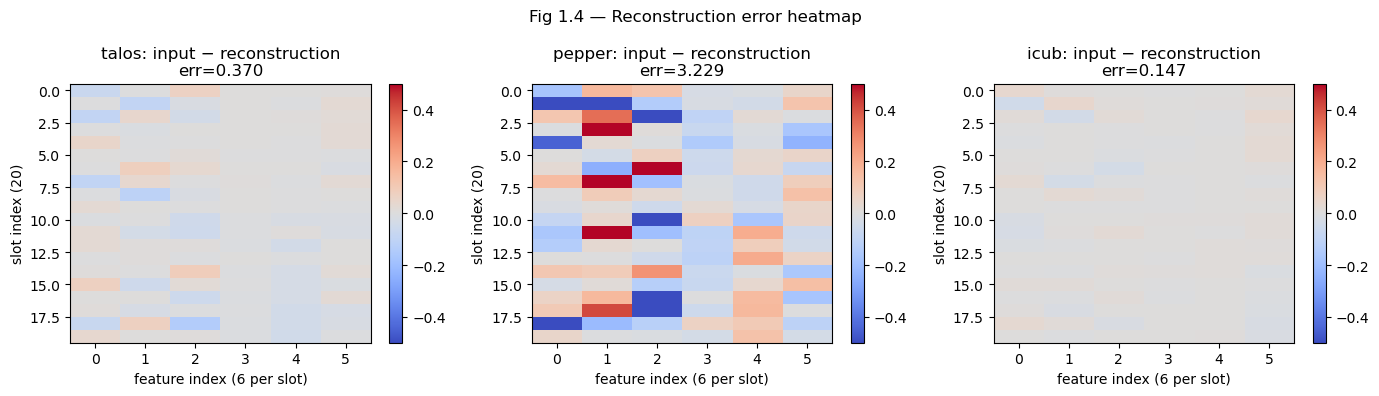

In [6]:
with th.no_grad():
    x_hat = ae.decode(th.tensor(z_all, dtype=th.float32)).numpy()
recon_err_per_robot = np.linalg.norm(data - x_hat, axis=1)

print('Reconstruction error per robot (L2):')
for i, (name, err) in enumerate(zip(label_data, recon_err_per_robot)):
    print(f'  [{i:2d}] {str(name):<12} err={err:.4f}')

# Show heatmap diff for talos/pepper/icub
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, robot in zip(axes, ['talos', 'pepper', 'icub']):
    idx = list(label_data).index(robot) if robot in [str(s) for s in label_data] else None
    if idx is None: continue
    diff = (data[idx] - x_hat[idx]).reshape(20, 6)
    im = ax.imshow(diff, aspect='auto', cmap='coolwarm', vmin=-0.5, vmax=0.5)
    ax.set_title(f'{robot}: input − reconstruction\nerr={recon_err_per_robot[idx]:.3f}')
    ax.set_xlabel('feature index (6 per slot)')
    ax.set_ylabel('slot index (20)')
    plt.colorbar(im, ax=ax)
plt.suptitle('Fig 1.4: Reconstruction error heatmap')
plt.tight_layout()
plt.show()

## 6. Decoder grid: what does latent space look like?

Sample a 5×5 meshgrid of z ∈ [-15,15]² and decode each to a 120D screw vector.
Show the axis-norm signature of each decoded robot (which joints are activated).

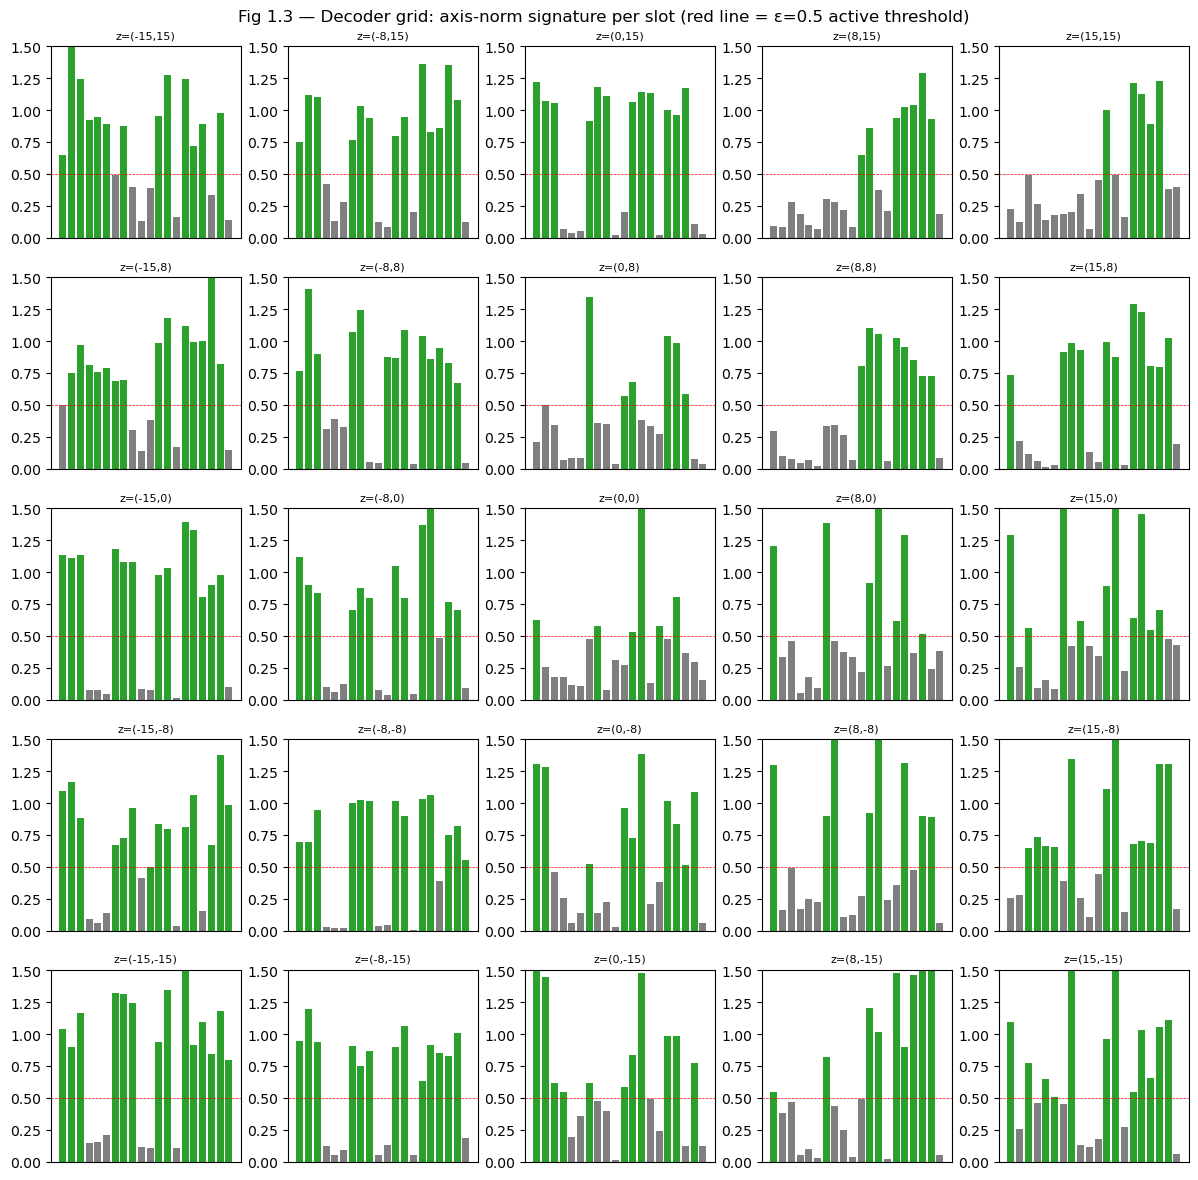

In [7]:
# 5×5 meshgrid
grid_n = 5
zs = np.linspace(-15, 15, grid_n)
mesh = np.array([[x, y] for y in zs[::-1] for x in zs])  # row-major top→bottom

with th.no_grad():
    decoded = ae.decode(th.tensor(mesh, dtype=th.float32)).numpy()  # (25, 120)

# For each decoded sample, compute axis-norm of each of 20 slots
axis_norms = np.linalg.norm(decoded.reshape(-1, 20, 6)[:, :, :3], axis=2)  # (25, 20)

# Show axis-norm signature as a 5×5 grid of mini-heatmaps
fig, axes = plt.subplots(grid_n, grid_n, figsize=(12, 12))
for i, ax in enumerate(axes.flat):
    ax.bar(range(20), axis_norms[i], color=['C2' if v >= 0.5 else 'C7' for v in axis_norms[i]])
    ax.axhline(0.5, color='red', linestyle='--', linewidth=0.5)
    ax.set_ylim(0, 1.5); ax.set_xticks([])
    z = mesh[i]
    ax.set_title(f'z=({z[0]:.0f},{z[1]:.0f})', fontsize=8)
plt.suptitle('Fig 1.3: Decoder grid: axis-norm signature per slot (red line = ε=0.5 active threshold)')
plt.tight_layout()
plt.show()

## 7. (Optional) Save artifacts to tutorial outputs

If `SAVE_OUTPUTS=True`, save the encoded latent positions + k-means labels for later sections.
Never writes to canonical paths.

In [8]:
if SAVE_OUTPUTS:
    out_path = os.path.join(TUTORIAL_OUT, 'section1_latent.npz')
    np.savez(out_path,
             z_all=z_all,
             labels=label_data,
             kmeans_labels=km.labels_,
             kmeans_centers=km.cluster_centers_,
             recon_err=recon_err_per_robot)
    print(f'Saved: {out_path}')
else:
    print('SAVE_OUTPUTS=False: skipping save. Set SAVE_OUTPUTS=True to write to outputs/.')

SAVE_OUTPUTS=False: skipping save. Set SAVE_OUTPUTS=True to write to outputs/.


---

## Summary
- Loaded 30 robots × 120D symmetric screw representation
- (Skipped or ran) AE training: 64→32→z=2, iso_reg=1e-7
- Encoded to 2D latent space, k=5 clusters
- Verified reconstruction quality
- Visualized decoder behavior on a meshgrid

**Next**: [`03_analysis_visualization.ipynb`](./03_analysis_visualization.ipynb): reproduce paper Table I + Figure 2/3 from canonical VOO summaries.

Or jump to [`02_design_optimization_voo.ipynb`](./02_design_optimization_voo.ipynb) to run a single-motion VOO demo.